# PBL 3 – Bayesian Model Averaging and Ensemble Learning

**Student:** Pratistha Chaira  
**Project:** Machine Learning-Driven Geomagnetic Storm Forecasting from Solar Wind Dynamics

## Objective

This notebook implements two techniques:

1. Bayesian Model Averaging (BMA)
2. Ensemble Learning using Stacking

The objective is to predict continuous Dst values using the processed solar-wind dataset.

The models will be evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

## 1. Accessing the Project Repository

The existing GitHub repository is used to access the team's processed dataset and maintain consistency with the earlier project work.

In [2]:
import os

%cd /content

!git clone https://github.com/swastiranjan/Geomagnetic-Storm-Prediction.git

%cd /content/Geomagnetic-Storm-Prediction

print("Current folder:", os.getcwd())

/content
Cloning into 'Geomagnetic-Storm-Prediction'...
remote: Enumerating objects: 111, done.
remote: Counting objects: 100% (111/111), done.
remote: Compressing objects: 100% (90/90), done.
remote: Total 111 (delta 21), reused 33 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (111/111), 9.41 MiB | 6.38 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/Geomagnetic-Storm-Prediction
Current folder: /content/Geomagnetic-Storm-Prediction


## 2. Inspecting the Dataset

Before loading the data, the repository is inspected to locate the existing chronological training, validation, and testing datasets.

In [3]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".git", ".ipynb_checkpoints"]]

    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

./data/processed/validation_final.csv
./data/processed/train_final.csv
./data/processed/feature_columns.csv
./data/processed/test_final.csv
./results/regression/final_metrics.csv
./results/regression/validation_comparison.csv
./results/regression/test_predictions.csv
./results/classification/test_metrics.csv
./results/classification/classification_metrics.csv
./results/classification/classification_predictions.csv
./results/analysis/classification_error_analysis.csv
./results/analysis/classification_analysis.csv


## 3. Importing Required Libraries

The following libraries are used for data handling, preprocessing, regression modelling, ensemble learning, and performance evaluation.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import statsmodels.api as sm
from pathlib import Path
import os
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Loading the Processed Dataset

The same processed chronological training, validation, and testing datasets used by the team are used in this implementation.

The training set is used to fit the models. The validation set is used to examine model performance during development, while the test set is reserved for final evaluation.

In [5]:
train_path = "./data/processed/train_final.csv"
validation_path = "./data/processed/validation_final.csv"
test_path = "./data/processed/test_final.csv"

train = pd.read_csv(train_path)
validation = pd.read_csv(validation_path)
test = pd.read_csv(test_path)

print("Training shape:", train.shape)
print("Validation shape:", validation.shape)
print("Testing shape:", test.shape)

display(train.head())

Training shape: (19349, 43)
Validation shape: (4141, 43)
Testing shape: (4142, 43)


,period,hour,bx_gse_mean,bx_gse_std,by_gse_mean,by_gse_std,bz_gse_mean,bz_gse_std,theta_gse_mean,theta_gse_std,...,bt,dynamic_pressure,delta_bz,delta_speed,delta_density,delta_bt,bz_south_3h_mean,bz_south_6h_mean,speed_3h_mean,density_3h_mean
0,train_a,0 days 06:00:00,-4.126364,1.367697,-4.238545,0.675515,0.857091,1.080214,7.516545,10.110191,...,6.635455,1.586910,0.118758,2.088375,-0.132672,0.269955,0.0,0.0,371.475058,3.917961
1,train_a,0 days 07:00:00,-1.965800,1.515395,-5.021800,0.807396,0.209200,1.355265,1.290800,12.566633,...,6.193200,1.657809,-0.647891,14.993830,-0.177708,-0.442255,0.0,0.0,388.337016,4.992391
2,train_a,0 days 08:00:00,-3.017667,1.031393,-4.386833,0.514240,0.636667,0.671411,6.137167,6.816736,...,5.885000,2.140559,0.427467,-7.346371,1.962314,-0.308200,0.0,0.0,402.702780,5.962488
3,train_a,0 days 09:00:00,-3.748333,0.857144,-3.406333,0.916484,1.138500,0.536908,11.600500,5.173960,...,5.728667,2.299433,0.501833,-9.673593,0.988067,-0.156333,0.0,0.0,405.948058,6.513132
4,train_a,0 days 10:00:00,-4.614833,0.320262,-2.613167,0.799200,2.127333,0.525608,20.269667,4.876620,...,6.148500,2.181783,0.988833,-5.527108,-0.211225,0.419833,0.0,0.0,405.272680,7.437356


## 5. Understanding the Dataset

The dataset columns are inspected to identify the Dst target variable and the predictor features.

The target variable must not be included among the input features.

In [6]:
print("Dataset columns:")
for col in train.columns:
    print(col)

print("\nData types:")
display(train.dtypes)

print("\nMissing values:")
display(train.isnull().sum())

Dataset columns:
period
hour
bx_gse_mean
bx_gse_std
by_gse_mean
by_gse_std
bz_gse_mean
bz_gse_std
theta_gse_mean
theta_gse_std
phi_gse_mean
phi_gse_std
bx_gsm_mean
bx_gsm_std
by_gsm_mean
by_gsm_std
bz_gsm_mean
bz_gsm_std
theta_gsm_mean
theta_gsm_std
phi_gsm_mean
phi_gsm_std
bt_mean
bt_std
density_mean
density_std
speed_mean
speed_std
temperature_mean
temperature_std
timedelta
dst
bz_south
bt
dynamic_pressure
delta_bz
delta_speed
delta_density
delta_bt
bz_south_3h_mean
bz_south_6h_mean
speed_3h_mean
density_3h_mean

Data types:


,0
period,object
hour,object
bx_gse_mean,float64
bx_gse_std,float64
by_gse_mean,float64
by_gse_std,float64
bz_gse_mean,float64
bz_gse_std,float64
theta_gse_mean,float64
theta_gse_std,float64



Missing values:


,0
period,0
hour,0
bx_gse_mean,0
bx_gse_std,0
by_gse_mean,0
by_gse_std,0
bz_gse_mean,0
bz_gse_std,0
theta_gse_mean,0
theta_gse_std,0


## 5. Selecting the Target and Input Features

The target variable for this project is `dst`, which represents the geomagnetic disturbance index.

Since this is a regression problem, the model will predict continuous Dst values.

The date and time columns (`period`, `hour`, and `timedelta`) will not be used as input features. All remaining numerical columns will be considered as input features.

In [7]:
# Define the target variable
target = "dst"

# Identify columns that should not be used as input features
excluded_columns = ["dst", "period", "hour", "timedelta"]

# Select numerical input features
feature_columns = [
    col for col in train.columns
    if col not in excluded_columns
    and pd.api.types.is_numeric_dtype(train[col])
]

# Separate features and target
X_train = train[feature_columns].copy()
y_train = train[target].copy()

X_val = validation[feature_columns].copy()
y_val = validation[target].copy()

X_test = test[feature_columns].copy()
y_test = test[target].copy()

print("Target variable:", target)
print("Number of input features:", len(feature_columns))
print("\nSelected features:")
print(feature_columns)

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Target variable: dst
Number of input features: 39

Selected features:
['bx_gse_mean', 'bx_gse_std', 'by_gse_mean', 'by_gse_std', 'bz_gse_mean', 'bz_gse_std', 'theta_gse_mean', 'theta_gse_std', 'phi_gse_mean', 'phi_gse_std', 'bx_gsm_mean', 'bx_gsm_std', 'by_gsm_mean', 'by_gsm_std', 'bz_gsm_mean', 'bz_gsm_std', 'theta_gsm_mean', 'theta_gsm_std', 'phi_gsm_mean', 'phi_gsm_std', 'bt_mean', 'bt_std', 'density_mean', 'density_std', 'speed_mean', 'speed_std', 'temperature_mean', 'temperature_std', 'bz_south', 'bt', 'dynamic_pressure', 'delta_bz', 'delta_speed', 'delta_density', 'delta_bt', 'bz_south_3h_mean', 'bz_south_6h_mean', 'speed_3h_mean', 'density_3h_mean']

Training shape: (19349, 39)
Validation shape: (4141, 39)
Testing shape: (4142, 39)


## 6. Data Preprocessing

The input features will be standardized so that they are on a comparable scale.

The scaler will be fitted only on the training dataset to prevent data leakage. The same transformation will then be applied to the validation and testing datasets.

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")
print("Training data:", X_train_scaled.shape)
print("Validation data:", X_val_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Feature scaling completed successfully.
Training data: (19349, 39)
Validation data: (4141, 39)
Testing data: (4142, 39)


## 7. Training Individual Regression Models

Three regression models will be trained as baseline models:

1. Linear Regression
2. Ridge Regression
3. Random Forest Regression

The models will be trained using the training dataset and evaluated on the validation dataset. The testing dataset will remain untouched until the final evaluation.

In [9]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

# Define the baseline models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    )
}

# Train models and generate validation predictions
validation_predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    validation_predictions[name] = model.predict(X_val_scaled)
    print(name, "trained successfully.")

print("\nAll baseline models have been trained.")

Linear Regression trained successfully.
Ridge Regression trained successfully.
Random Forest trained successfully.

All baseline models have been trained.


## 8. Evaluating Baseline Regression Models

The models will be evaluated using three regression metrics:

- **MAE:** Measures the average absolute prediction error.
- **RMSE:** Measures prediction error while penalizing larger errors more strongly.
- **R² Score:** Measures how much variation in Dst is explained by the model.

Lower MAE and RMSE values and a higher R² score indicate better performance.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_results = []

for name, predictions in validation_predictions.items():
    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    baseline_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

baseline_metrics = pd.DataFrame(baseline_results)

display(baseline_metrics.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,15.4572,22.7063,0.4802
1,Ridge Regression,15.5969,22.8819,0.4721
2,Random Forest,15.4794,23.6762,0.4348


## 9. Bayesian Model Averaging (BMA)

Bayesian Model Averaging combines predictions from multiple candidate models instead of relying on only one model.

Each candidate model receives a weight based on its relative support in the training data. Models with stronger support receive higher weights.

For this implementation, BIC (Bayesian Information Criterion) will be used to calculate approximate model weights. This is a BIC-based approximation to Bayesian Model Averaging, rather than a full posterior-based Bayesian implementation.

We will create candidate linear regression models using different numbers of top-ranked features and combine their predictions using the calculated weights.

In [11]:
# Rank features using their absolute correlation with Dst
feature_correlations = X_train.corrwith(y_train).abs().sort_values(
    ascending=False
)

print("Top 10 features related to Dst:")
display(feature_correlations.head(10).to_frame("Absolute Correlation"))

# Select different feature subset sizes
candidate_sizes = [3, 5, 8]

candidate_features = {}

for size in candidate_sizes:
    selected = feature_correlations.head(size).index.tolist()
    candidate_features[f"Model_{size}"] = selected

print("\nCandidate models and their features:")

for model_name, features in candidate_features.items():
    print(f"\n{model_name}:")
    print(features)

Top 10 features related to Dst:


,Absolute Correlation
bz_south_6h_mean,0.504139
bz_south_3h_mean,0.448242
speed_3h_mean,0.443654
speed_mean,0.430479
bz_south,0.278836
bt_mean,0.244602
bt,0.244602
temperature_mean,0.234523
bz_gsm_mean,0.216301
temperature_std,0.177746



Candidate models and their features:

Model_3:
['bz_south_6h_mean', 'bz_south_3h_mean', 'speed_3h_mean']

Model_5:
['bz_south_6h_mean', 'bz_south_3h_mean', 'speed_3h_mean', 'speed_mean', 'bz_south']

Model_8:
['bz_south_6h_mean', 'bz_south_3h_mean', 'speed_3h_mean', 'speed_mean', 'bz_south', 'bt_mean', 'bt', 'temperature_mean']


### Calculating BMA Model Weights

Each candidate model will be fitted using training data only.

The BIC value will be calculated for each model. Lower BIC indicates stronger relative support.

The BIC values will then be converted into normalized model weights. These weights will be used to combine the candidate models' validation predictions.

In [12]:
import statsmodels.api as sm

bma_models = {}
bma_bic_values = {}
bma_validation_predictions = {}

# Fit candidate models
for model_name, features in candidate_features.items():

    # Get feature positions
    feature_indices = [
        feature_columns.index(feature) for feature in features
    ]

    X_candidate_train = X_train_scaled[:, feature_indices]
    X_candidate_val = X_val_scaled[:, feature_indices]

    # Add intercept
    X_candidate_train_sm = sm.add_constant(
        X_candidate_train, has_constant="add"
    )

    X_candidate_val_sm = sm.add_constant(
        X_candidate_val, has_constant="add"
    )

    # Fit OLS model
    fitted_model = sm.OLS(
        y_train,
        X_candidate_train_sm
    ).fit()

    # Store model and BIC
    bma_models[model_name] = fitted_model
    bma_bic_values[model_name] = fitted_model.bic

    # Generate validation predictions
    bma_validation_predictions[model_name] = fitted_model.predict(
        X_candidate_val_sm
    )

# Convert BIC values into approximate model weights
bic_values = pd.Series(bma_bic_values)

delta_bic = bic_values - bic_values.min()

relative_support = np.exp(-0.5 * delta_bic)

bma_weights = relative_support / relative_support.sum()

# Combine candidate predictions
bma_val_prediction = np.zeros(len(y_val))

for model_name, weight in bma_weights.items():
    bma_val_prediction += (
        weight * bma_validation_predictions[model_name]
    )

# Display model weights
bma_weights_table = pd.DataFrame({
    "Model": bma_weights.index,
    "BIC": bic_values.values,
    "BMA Weight": bma_weights.values
})

display(bma_weights_table.round(4))

print("BMA validation predictions generated successfully.")

,Model,BIC,BMA Weight
0,Model_3,166751.5532,0.0
1,Model_5,166673.0022,0.0
2,Model_8,166484.1387,1.0


BMA validation predictions generated successfully.


## 10. Evaluating Bayesian Model Averaging

The BMA predictions will be evaluated using MAE, RMSE, and R² score.

Its performance will also be compared with the individual regression models to determine whether combining candidate models improves prediction accuracy.

In [13]:
# Evaluate BMA
bma_mae = mean_absolute_error(y_val, bma_val_prediction)
bma_rmse = np.sqrt(mean_squared_error(y_val, bma_val_prediction))
bma_r2 = r2_score(y_val, bma_val_prediction)

bma_result = pd.DataFrame([{
    "Model": "Bayesian Model Averaging",
    "MAE": bma_mae,
    "RMSE": bma_rmse,
    "R2 Score": bma_r2
}])

display(bma_result.round(4))

,Model,MAE,RMSE,R2 Score
0,Bayesian Model Averaging,15.8248,23.1096,0.4615


In [14]:
# Combine baseline and BMA results
comparison_results = pd.concat(
    [baseline_metrics, bma_result],
    ignore_index=True
)

print("Validation Performance Comparison:")
display(comparison_results.round(4))

Validation Performance Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,15.4572,22.7063,0.4802
1,Ridge Regression,15.5969,22.8819,0.4721
2,Random Forest,15.4794,23.6762,0.4348
3,Bayesian Model Averaging,15.8248,23.1096,0.4615


## 11. Stacking Ensemble Learning

Stacking is an ensemble learning technique that combines predictions from multiple base models using another model called a meta-model.

In this project:

- Base models: Linear Regression, Ridge Regression and Random Forest.
- Meta-model: Ridge Regression.

Time Series Split cross-validation will generate out-of-fold predictions for training the meta-model. This preserves chronological order and prevents the meta-model from learning from predictions made on the same observations used to fit the base models.

In [15]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

# Define base models with preprocessing inside each model
base_models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Random Forest": make_pipeline(
        StandardScaler(),
        RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )
    )
}

# Create time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Store out-of-fold predictions
oof_predictions = np.full(
    (len(X_train), len(base_models)),
    np.nan
)

for fold, (train_indices, validation_indices) in enumerate(
    tscv.split(X_train), start=1
):
    for model_index, (name, model) in enumerate(base_models.items()):

        fold_model = clone(model)

        fold_model.fit(
            X_train.iloc[train_indices],
            y_train.iloc[train_indices]
        )

        oof_predictions[validation_indices, model_index] = (
            fold_model.predict(X_train.iloc[validation_indices])
        )

    print(f"Fold {fold} completed.")

# Keep only observations with out-of-fold predictions
valid_oof = ~np.isnan(oof_predictions).any(axis=1)

X_meta_train = oof_predictions[valid_oof]
y_meta_train = y_train.iloc[np.where(valid_oof)[0]]

print("\nOut-of-fold prediction generation completed.")
print("Meta-model training shape:", X_meta_train.shape)

Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.

Out-of-fold prediction generation completed.
Meta-model training shape: (16120, 3)


### Training the Stacking Meta-Model

The out-of-fold predictions from the base models will be used to train a Ridge Regression meta-model.

After training, the base models will be fitted on the complete training dataset. Their validation predictions will then be passed to the meta-model to generate the final Stacking predictions.

In [17]:
# Train the meta-model
meta_model = Ridge(alpha=1.0)
meta_model.fit(X_meta_train, y_meta_train)

# Fit base models on the complete training dataset
fitted_base_models = {}

for name, model in base_models.items():
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)

    fitted_base_models[name] = fitted_model

# Generate validation predictions from each base model
stacking_val_base_predictions = np.column_stack([
    fitted_base_models[name].predict(X_val)
    for name in base_models.keys()
])

# Generate final Stacking validation predictions
stacking_val_prediction = meta_model.predict(
    stacking_val_base_predictions
)

print("Stacking validation predictions generated successfully.")

Stacking validation predictions generated successfully.


## 12. Evaluating the Stacking Model

The Stacking model will be evaluated using MAE, RMSE and R² score.

Its performance will be compared with the individual regression models and Bayesian Model Averaging.

In [18]:
# Evaluate Stacking
stacking_mae = mean_absolute_error(
    y_val, stacking_val_prediction
)

stacking_rmse = np.sqrt(mean_squared_error(
    y_val, stacking_val_prediction
))

stacking_r2 = r2_score(
    y_val, stacking_val_prediction
)

stacking_result = pd.DataFrame([{
    "Model": "Stacking",
    "MAE": stacking_mae,
    "RMSE": stacking_rmse,
    "R2 Score": stacking_r2
}])

# Compare all validation results
all_validation_results = pd.concat(
    [comparison_results, stacking_result],
    ignore_index=True
)

print("Complete Validation Performance Comparison:")
display(all_validation_results.round(4))

Complete Validation Performance Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,15.4572,22.7063,0.4802
1,Ridge Regression,15.5969,22.8819,0.4721
2,Random Forest,15.4794,23.6762,0.4348
3,Bayesian Model Averaging,15.8248,23.1096,0.4615
4,Stacking,15.5813,23.1810,0.4582


## 13. Final Model Training and Testing

The training and validation datasets will now be combined to create the final training dataset.

All models will be refitted using this combined dataset. The test dataset will remain separate and will be used only for final evaluation.

A new scaler will be fitted on the combined training data to ensure consistent preprocessing.

In [19]:
# Combine training and validation datasets
X_trainval = pd.concat(
    [X_train, X_val],
    ignore_index=True
)

y_trainval = pd.concat(
    [y_train, y_val],
    ignore_index=True
)

# Fit a fresh scaler on combined training data
final_scaler = StandardScaler()

X_trainval_scaled = final_scaler.fit_transform(X_trainval)
X_test_final_scaled = final_scaler.transform(X_test)

print("Combined training shape:", X_trainval.shape)
print("Final testing shape:", X_test.shape)
print("Final preprocessing completed.")

Combined training shape: (23490, 39)
Final testing shape: (4142, 39)
Final preprocessing completed.


### Final Training of Individual Models and BMA

The three baseline regression models will be refitted using the combined training and validation datasets.

The BMA candidate models will also be refitted. Their feature rankings, BIC values and approximate model weights will be recalculated using the combined training data.

The final predictions will be generated on the untouched test dataset.

In [21]:
# Train final individual regression models
final_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

final_test_predictions = {}

for name, model in final_models.items():
    model.fit(X_trainval_scaled, y_trainval)
    final_test_predictions[name] = model.predict(
        X_test_final_scaled
    )

# Recalculate feature rankings using combined training data
final_correlations = (
    X_trainval.corrwith(y_trainval)
    .abs()
    .sort_values(ascending=False)
)

final_candidate_features = {
    f"Model_{size}": final_correlations.head(size).index.tolist()
    for size in [3, 5, 8]
}

# Fit final BMA candidate models
final_bma_models = {}
final_bma_bic = {}
final_bma_candidate_predictions = {}

for model_name, features in final_candidate_features.items():

    indices = [
        feature_columns.index(feature)
        for feature in features
    ]

    X_candidate_train = X_trainval_scaled[:, indices]
    X_candidate_test = X_test_final_scaled[:, indices]

    X_candidate_train_sm = sm.add_constant(
        X_candidate_train, has_constant="add"
    )

    X_candidate_test_sm = sm.add_constant(
        X_candidate_test, has_constant="add"
    )

    fitted_model = sm.OLS(
        y_trainval,
        X_candidate_train_sm
    ).fit()

    final_bma_models[model_name] = fitted_model
    final_bma_bic[model_name] = fitted_model.bic

    final_bma_candidate_predictions[model_name] = (
        fitted_model.predict(X_candidate_test_sm)
    )

# Calculate final BMA weights
final_bic_series = pd.Series(final_bma_bic)

final_relative_support = np.exp(
    -0.5 * (final_bic_series - final_bic_series.min())
)

final_bma_weights = (
    final_relative_support / final_relative_support.sum()
)

# Combine final BMA predictions
final_bma_prediction = np.zeros(len(y_test))

for model_name, weight in final_bma_weights.items():
    final_bma_prediction += (
        weight * final_bma_candidate_predictions[model_name]
    )

final_test_predictions["Bayesian Model Averaging"] = (
    final_bma_prediction
)

print("Final baseline and BMA predictions generated.")

display(pd.DataFrame({
    "Model": final_bma_weights.index,
    "BIC": final_bma_weights.values * 0 + final_bic_series.values,
    "BMA Weight": final_bma_weights.values
}).round(6))

Final baseline and BMA predictions generated.


,Model,BIC,BMA Weight
0,Model_3,205233.921694,0.0
1,Model_5,205190.792472,0.0
2,Model_8,204945.510587,1.0


### Final Training of the Stacking Model

The Stacking model will be retrained using the combined training and validation datasets.

Time Series Split will generate out-of-fold predictions for the base models. These predictions will train the Ridge Regression meta-model.

The final base models will then be fitted on the complete combined dataset and used to generate test predictions.

In [22]:
# Generate out-of-fold predictions on combined training data
final_oof_predictions = np.full(
    (len(X_trainval), len(base_models)),
    np.nan
)

final_tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_indices, validation_indices) in enumerate(
    final_tscv.split(X_trainval), start=1
):

    for model_index, (name, model) in enumerate(base_models.items()):

        fold_model = clone(model)

        fold_model.fit(
            X_trainval.iloc[train_indices],
            y_trainval.iloc[train_indices]
        )

        final_oof_predictions[validation_indices, model_index] = (
            fold_model.predict(
                X_trainval.iloc[validation_indices]
            )
        )

    print(f"Final Stacking fold {fold} completed.")

# Keep only rows with out-of-fold predictions
final_valid_oof = ~np.isnan(final_oof_predictions).any(axis=1)

X_final_meta = final_oof_predictions[final_valid_oof]
y_final_meta = y_trainval.iloc[
    np.where(final_valid_oof)[0]
]

# Train final meta-model
final_meta_model = Ridge(alpha=1.0)
final_meta_model.fit(X_final_meta, y_final_meta)

# Refit base models on complete combined dataset
final_fitted_base_models = {}

for name, model in base_models.items():

    fitted_model = clone(model)

    fitted_model.fit(X_trainval, y_trainval)

    final_fitted_base_models[name] = fitted_model

# Generate test predictions from base models
final_stacking_base_predictions = np.column_stack([
    final_fitted_base_models[name].predict(X_test)
    for name in base_models.keys()
])

# Generate final Stacking prediction
final_stacking_prediction = final_meta_model.predict(
    final_stacking_base_predictions
)

final_test_predictions["Stacking"] = final_stacking_prediction

print("Final Stacking predictions generated successfully.")

Final Stacking fold 1 completed.
Final Stacking fold 2 completed.
Final Stacking fold 3 completed.
Final Stacking fold 4 completed.
Final Stacking fold 5 completed.
Final Stacking predictions generated successfully.


## 14. Final Performance Evaluation

All five models will now be evaluated on the untouched test dataset.

MAE, RMSE and R² score will be used to compare their final predictive performance.

These results represent the final evaluation of the individual regression models, Bayesian Model Averaging and Stacking.

In [23]:
final_results = []

for name, predictions in final_test_predictions.items():

    final_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

final_metrics = pd.DataFrame(final_results)

print("FINAL TEST PERFORMANCE COMPARISON")
display(final_metrics.round(4))

best_model = final_metrics.sort_values(
    by="RMSE"
).iloc[0]

print("\nBest model based on test RMSE:", best_model["Model"])

FINAL TEST PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,13.4293,21.1548,0.5527
1,Ridge Regression,13.4695,21.2005,0.5508
2,Random Forest,13.9618,21.4256,0.5412
3,Bayesian Model Averaging,15.2391,23.4962,0.4482
4,Stacking,13.1587,21.4028,0.5422



Best model based on test RMSE: Linear Regression


## 15. Saving Model Results

The final performance metrics, test predictions and Bayesian Model Averaging weights will be saved as CSV files.

These files will be used for result analysis, visualization, presentation and documentation.

In [24]:
# Create folder for PBL 3 results
from pathlib import Path

results_dir = Path("results/pratistha_pbl3")
results_dir.mkdir(parents=True, exist_ok=True)

# Save final test metrics
final_metrics.to_csv(
    results_dir / "final_test_metrics.csv",
    index=False
)

# Save validation metrics
all_validation_results.to_csv(
    results_dir / "validation_metrics.csv",
    index=False
)

# Save final BMA weights
final_bma_weights_table = pd.DataFrame({
    "Model": final_bma_weights.index,
    "BIC": [final_bma_bic[name] for name in final_bma_weights.index],
    "BMA Weight": final_bma_weights.values
})

final_bma_weights_table.to_csv(
    results_dir / "final_bma_weights.csv",
    index=False
)

# Save actual and predicted Dst values
predictions_df = pd.DataFrame({
    "Actual_Dst": np.asarray(y_test)
})

for model_name, predictions in final_test_predictions.items():
    predictions_df[model_name.replace(" ", "_")] = predictions

predictions_df.to_csv(
    results_dir / "final_test_predictions.csv",
    index=False
)

print("All CSV files saved successfully.")
print("\nFiles saved in:", results_dir.resolve())

for file in sorted(results_dir.iterdir()):
    print(file.name)

All CSV files saved successfully.

Files saved in: /content/Geomagnetic-Storm-Prediction/results/pratistha_pbl3
final_bma_weights.csv
final_test_metrics.csv
final_test_predictions.csv
validation_metrics.csv


## 16. Result Visualization

Graphs will be generated to compare the performance of the regression models and understand their prediction behaviour.

The visualizations include:

1. Model comparison using MAE.
2. Model comparison using RMSE.
3. Model comparison using R² score.
4. Actual versus predicted Dst values.
5. Bayesian Model Averaging weights.

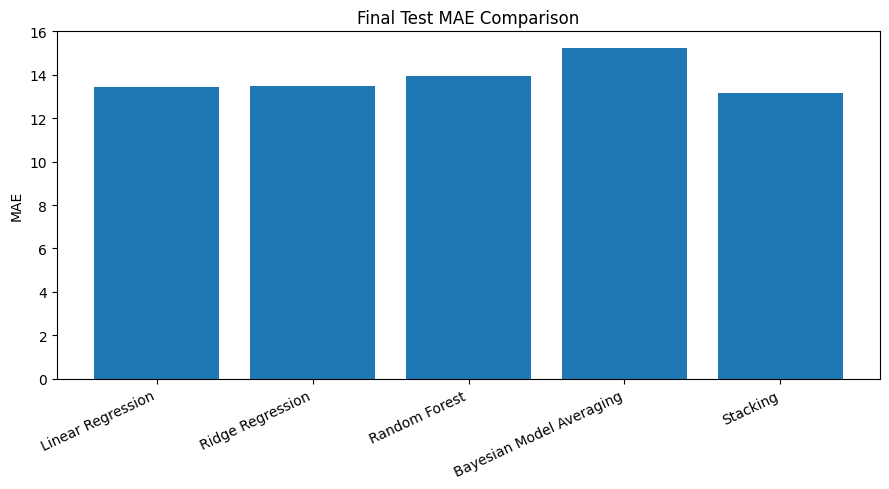

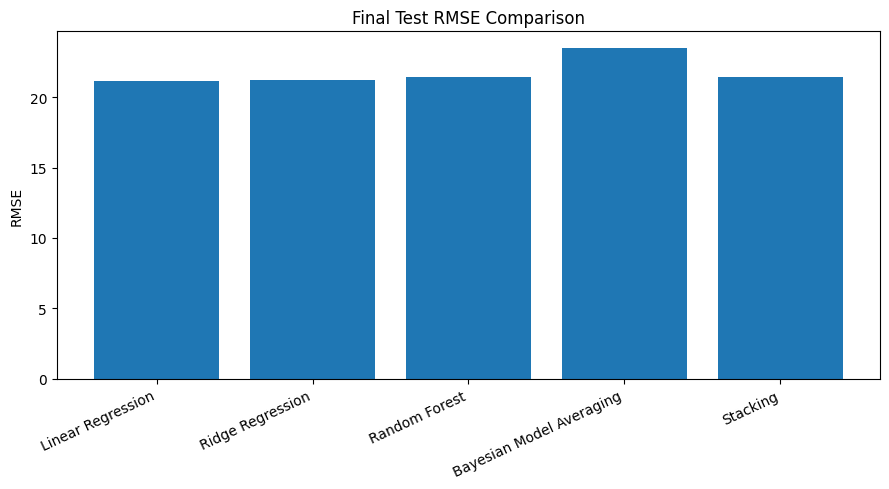

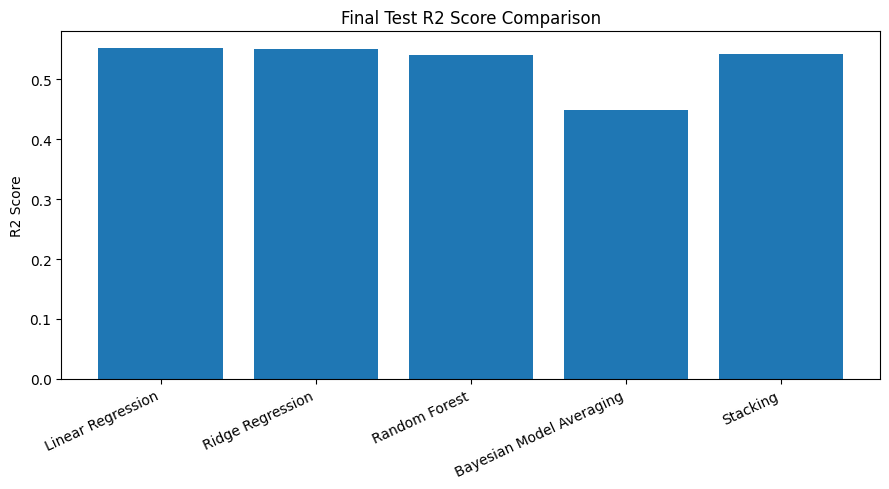

Model comparison graphs saved successfully.


In [25]:
# MAE comparison
plt.figure(figsize=(9, 5))
plt.bar(final_metrics["Model"], final_metrics["MAE"])
plt.title("Final Test MAE Comparison")
plt.ylabel("MAE")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(results_dir / "mae_comparison.png", dpi=300)
plt.show()

# RMSE comparison
plt.figure(figsize=(9, 5))
plt.bar(final_metrics["Model"], final_metrics["RMSE"])
plt.title("Final Test RMSE Comparison")
plt.ylabel("RMSE")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(results_dir / "rmse_comparison.png", dpi=300)
plt.show()

# R2 comparison
plt.figure(figsize=(9, 5))
plt.bar(final_metrics["Model"], final_metrics["R2 Score"])
plt.title("Final Test R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(results_dir / "r2_comparison.png", dpi=300)
plt.show()

print("Model comparison graphs saved successfully.")

## 17. Actual vs Predicted Dst Visualization

This graph compares the actual Dst values with the values predicted by the Stacking model.

It helps us understand how closely the model predictions follow the actual geomagnetic variations.

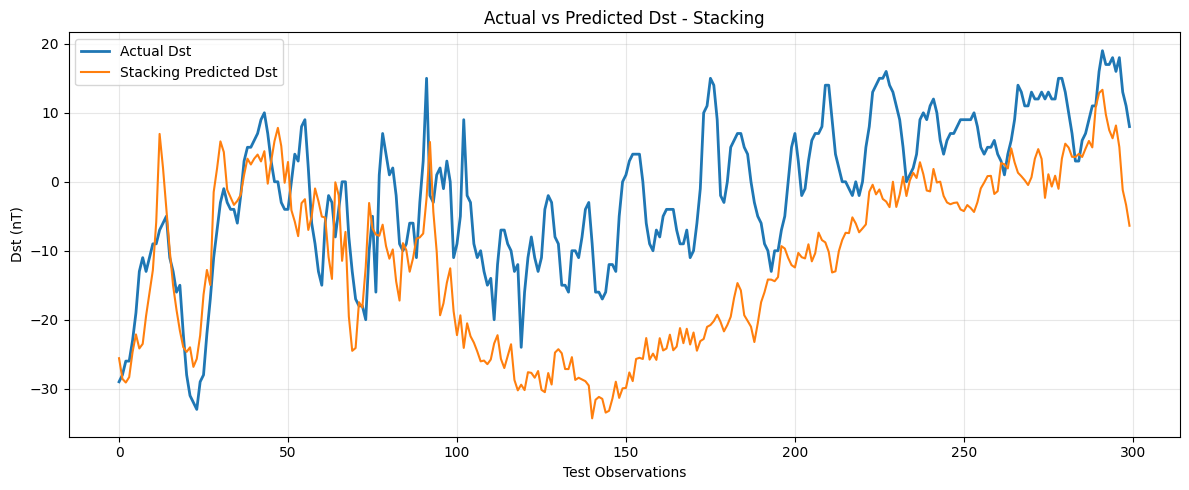

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.asarray(y_test)[:300],
    label="Actual Dst",
    linewidth=2
)

plt.plot(
    final_test_predictions["Stacking"][:300],
    label="Stacking Predicted Dst",
    linewidth=1.5
)

plt.title("Actual vs Predicted Dst - Stacking")
plt.xlabel("Test Observations")
plt.ylabel("Dst (nT)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_dir / "actual_vs_predicted_stacking.png",
    dpi=300
)

plt.show()

## 18. Bayesian Model Averaging Weights

This visualization shows the approximate BMA weights assigned to each candidate model.

A higher weight indicates stronger relative support according to the BIC-based weighting approach used in this experiment.

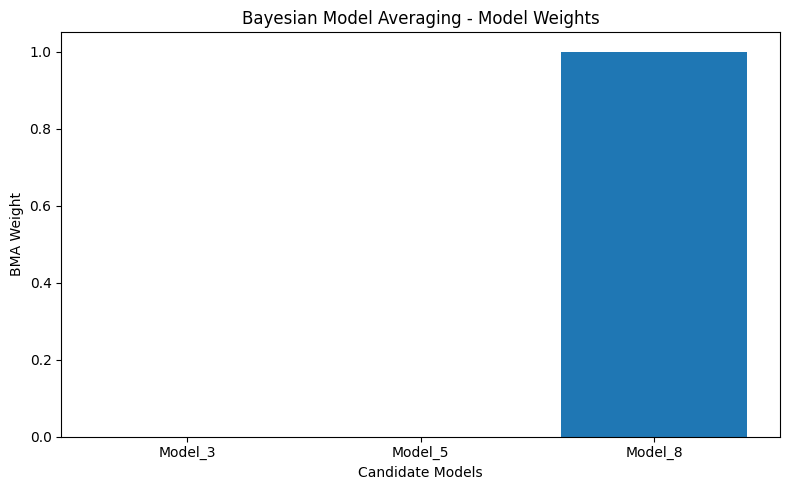

Remaining visualizations saved successfully.


In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    final_bma_weights.index,
    final_bma_weights.values
)

plt.title("Bayesian Model Averaging - Model Weights")
plt.xlabel("Candidate Models")
plt.ylabel("BMA Weight")
plt.tight_layout()

plt.savefig(
    results_dir / "bma_model_weights.png",
    dpi=300
)

plt.show()

print("Remaining visualizations saved successfully.")

In [28]:
print("FINAL PBL 3 RESULTS FOLDER")
print("--------------------------")

for file in sorted(results_dir.iterdir()):
    print(file.name)

print("\nTotal files:", len(list(results_dir.iterdir())))

FINAL PBL 3 RESULTS FOLDER
--------------------------
actual_vs_predicted_stacking.png
bma_model_weights.png
final_bma_weights.csv
final_test_metrics.csv
final_test_predictions.csv
mae_comparison.png
r2_comparison.png
rmse_comparison.png
validation_metrics.csv

Total files: 9
